In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## grouped-bar-chart

**Figure 1: Accuracy of four training methods on GSM8K, MATH and HumanEval.** Ours is the most accurate on all three benchmarks, ahead of the best baseline, DPO, by 3.6, 4.3 and 2.9 points.

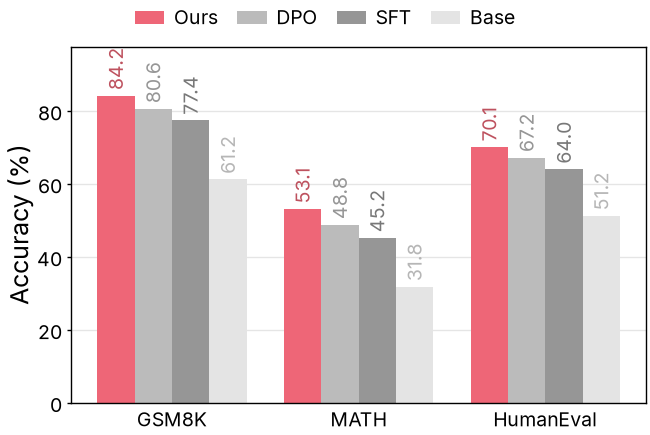

In [2]:
with open("../grouped-bar-chart.json") as f:
    data = json.load(f)
benchmarks = data["benchmarks"]

methods = ["Ours", "DPO", "SFT", "Base"]
method_colors = {
    "Ours": colors["ours"],
    "DPO": colors["neutral"],
    "SFT": darken(colors["neutral"]),
    "Base": lighten(colors["neutral"]),
}

fig, ax = plt.subplots(figsize=(3.25, 2))
x = np.arange(len(benchmarks))
width = 0.8 / len(methods)
for i, method in enumerate(methods):
    accuracy = 100 * np.array(data["scores"][method])
    bars = ax.bar(x + (i - (len(methods) - 1) / 2) * width, accuracy, width,
                  color=method_colors[method], linewidth=0, label=method)
    ax.bar_label(bars, fmt="%.1f", color=darken(method_colors[method]), rotation=90, padding=2)

ax.set_xticks(x, labels=benchmarks)
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Accuracy (%)")
fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=4, frameon=False, borderaxespad=0)

fit_height(fig, ax, aspect=0.618)
fig.savefig("grouped-bar-chart.pdf")
fig.savefig("grouped-bar-chart.png")
plt.show()